In [3]:
# import os

# print(os.path.abspath("Day18_funnel_Analysis.ipynb"))

import os

print(os.getcwd())

C:\Users\immek


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset using your file path
df = pd.read_csv(r"C:\Users\immek\Funnel_Analysis_Data.csv")

# Display first 5 rows
df.head()

,User ID,Session ID,Event Time,Event,Device,Region,Channel,Product Category,Revenue,Bonus Flag
0,USR-00001,SES-00001,2026-01-07 23:46:20.358501,Browse,Tablet,South,Organic,Electronics,0.0,Yes
1,USR-00001,SES-00001,2026-01-07 23:49:20.358501,Add to Cart,Tablet,South,Organic,Electronics,0.0,Yes
2,USR-00001,SES-00001,2026-01-07 23:51:20.358501,Checkout,Tablet,South,Organic,Electronics,0.0,Yes
3,USR-00002,SES-00002,2026-01-04 21:06:42.296010,Browse,Desktop,East,Email,Sports,0.0,Yes
4,USR-00002,SES-00002,2026-01-04 21:10:42.296010,Add to Cart,Desktop,East,Email,Sports,0.0,Yes


In [6]:
# Check dataset information
df.info()

# Check missing values
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check event counts
print(df["Event"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21409 entries, 0 to 21408
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User ID           21409 non-null  object 
 1   Session ID        21409 non-null  object 
 2   Event Time        21409 non-null  object 
 3   Event             21409 non-null  object 
 4   Device            21409 non-null  object 
 5   Region            21409 non-null  object 
 6   Channel           21409 non-null  object 
 7   Product Category  21409 non-null  object 
 8   Revenue           21409 non-null  float64
 9   Bonus Flag        21409 non-null  object 
dtypes: float64(1), object(9)
memory usage: 1.6+ MB
User ID             0
Session ID          0
Event Time          0
Event               0
Device              0
Region              0
Channel             0
Product Category    0
Revenue             0
Bonus Flag          0
dtype: int64
Duplicate rows: 0
Event
Browse         100

In [8]:
# Define funnel stages
stages = ["Browse", "Add to Cart", "Checkout", "Purchase"]

# Count unique users at each stage
funnel_counts = [
    df[df["Event"] == stage]["User ID"].nunique()
    for stage in stages
]

# Create funnel table
funnel = pd.DataFrame({
    "Stage": stages,
    "Users": funnel_counts
})

# Calculate conversion rate
funnel["Conversion Rate (%)"] = (
    funnel["Users"] / funnel["Users"].shift(1) * 100
)

funnel.loc[0, "Conversion Rate (%)"] = 100

# Calculate drop-off
funnel["Drop-off Users"] = (
    funnel["Users"].shift(1) - funnel["Users"]
)

funnel["Drop-off (%)"] = (
    funnel["Drop-off Users"] / funnel["Users"].shift(1) * 100
)

funnel = funnel.fillna(0)

funnel

,Stage,Users,Conversion Rate (%),Drop-off Users,Drop-off (%)
0,Browse,10000,100.000000,0.0,0.000000
1,Add to Cart,6949,69.490000,3051.0,30.510000
2,Checkout,3456,49.733775,3493.0,50.266225
3,Purchase,1004,29.050926,2452.0,70.949074


In [9]:
# Identify the stage with the highest drop-off
max_dropoff = funnel.loc[funnel["Drop-off Users"].idxmax()]

print("Highest Drop-off Stage:")
print("Stage:", max_dropoff["Stage"])
print("Users Lost:", int(max_dropoff["Drop-off Users"]))
print("Drop-off Percentage:", round(max_dropoff["Drop-off (%)"], 2), "%")

# Identify highest drop-off percentage
max_percentage = funnel.loc[funnel["Drop-off (%)"].idxmax()]

print("\nHighest Drop-off Percentage:")
print("Stage:", max_percentage["Stage"])
print("Drop-off:", round(max_percentage["Drop-off (%)"], 2), "%")

Highest Drop-off Stage:
Stage: Checkout
Users Lost: 3493
Drop-off Percentage: 50.27 %

Highest Drop-off Percentage:
Stage: Purchase
Drop-off: 70.95 %


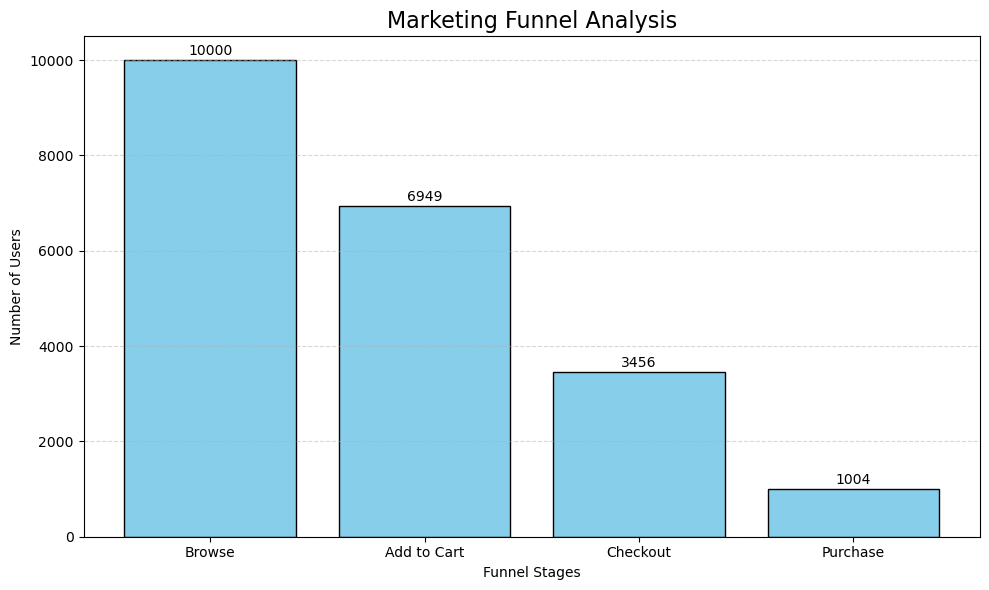

In [10]:
plt.figure(figsize=(10, 6))

plt.bar(
    funnel["Stage"],
    funnel["Users"],
    color="skyblue",
    edgecolor="black"
)

plt.title("Marketing Funnel Analysis", fontsize=16)
plt.xlabel("Funnel Stages")
plt.ylabel("Number of Users")

for i, value in enumerate(funnel["Users"]):
    plt.text(i, value + 100, str(value), ha="center")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [11]:
# Conversion rate by device

device_funnel = df.pivot_table(
    index="Device",
    columns="Event",
    values="User ID",
    aggfunc="nunique",
    fill_value=0
)

# Calculate purchase conversion rate
device_funnel["Conversion Rate (%)"] = (
    device_funnel["Purchase"] /
    device_funnel["Browse"] * 100
)

device_funnel["Conversion Rate (%)"] = (
    device_funnel["Conversion Rate (%)"].round(2)
)

device_funnel

Event,Add to Cart,Browse,Checkout,Purchase,Conversion Rate (%)
Device,,,,,
Desktop,2367,3366,1182,356,10.58
Mobile,2253,3263,1123,309,9.47
Tablet,2329,3371,1151,339,10.06


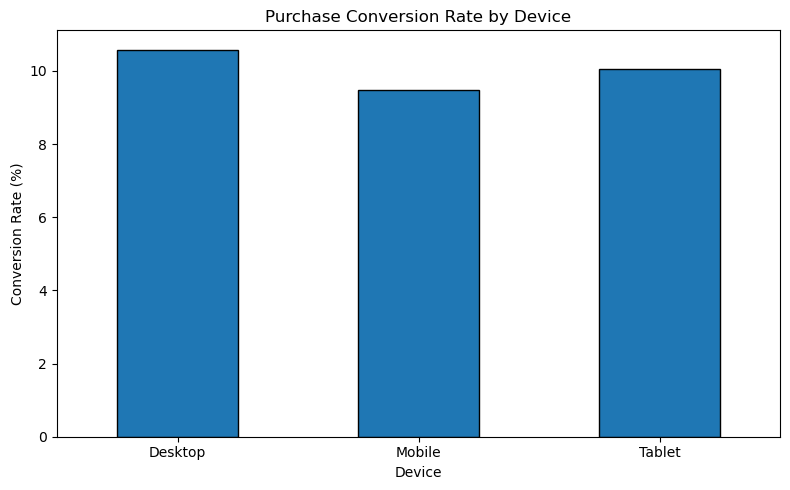

In [12]:
device_funnel["Conversion Rate (%)"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Purchase Conversion Rate by Device",
    edgecolor="black"
)

plt.ylabel("Conversion Rate (%)")
plt.xlabel("Device")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
# Conversion rate by marketing channel

channel_funnel = df.pivot_table(
    index="Channel",
    columns="Event",
    values="User ID",
    aggfunc="nunique",
    fill_value=0
)

# Calculate purchase conversion rate
channel_funnel["Conversion Rate (%)"] = (
    channel_funnel["Purchase"] /
    channel_funnel["Browse"] * 100
).round(2)

# Display results
channel_funnel

Event,Add to Cart,Browse,Checkout,Purchase,Conversion Rate (%)
Channel,,,,,
Email,1762,2515,879,248,9.86
Google Ads,1746,2520,893,268,10.63
Organic,1745,2528,866,239,9.45
Social Media,1696,2437,818,249,10.22


In [14]:
best_channel = channel_funnel[
    "Conversion Rate (%)"
].idxmax()

best_rate = channel_funnel[
    "Conversion Rate (%)"
].max()

print("Best Marketing Channel:", best_channel)
print("Conversion Rate:", best_rate, "%")

Best Marketing Channel: Google Ads
Conversion Rate: 10.63 %


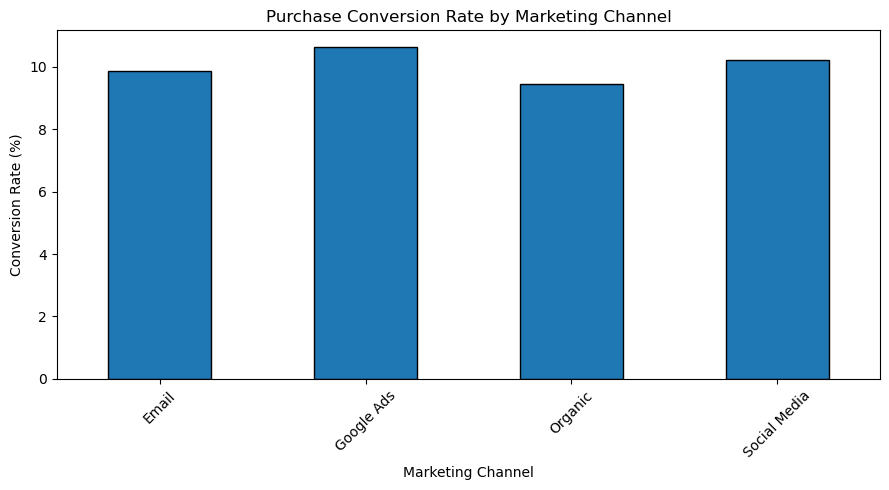

In [15]:
channel_funnel["Conversion Rate (%)"].plot(
    kind="bar",
    figsize=(9, 5),
    edgecolor="black",
    title="Purchase Conversion Rate by Marketing Channel"
)

plt.xlabel("Marketing Channel")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
# Analyze purchases by product category

category_analysis = df.pivot_table(
    index="Product Category",
    columns="Event",
    values="User ID",
    aggfunc="nunique",
    fill_value=0
)

category_analysis

Event,Add to Cart,Browse,Checkout,Purchase
Product Category,,,,
Beauty,1428,2021,713,191
Electronics,1443,2052,711,229
Fashion,1385,2001,692,211
Home,1357,1978,666,184
Sports,1336,1948,674,189


In [17]:
# Calculate total revenue for purchases only

revenue_analysis = (
    df[df["Event"] == "Purchase"]
    .groupby("Product Category")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Revenue by Product Category:")
print(revenue_analysis)

Revenue by Product Category:
Product Category
Electronics    62938.46
Fashion        58075.22
Sports         55856.01
Beauty         50353.36
Home           50100.01
Name: Revenue, dtype: float64


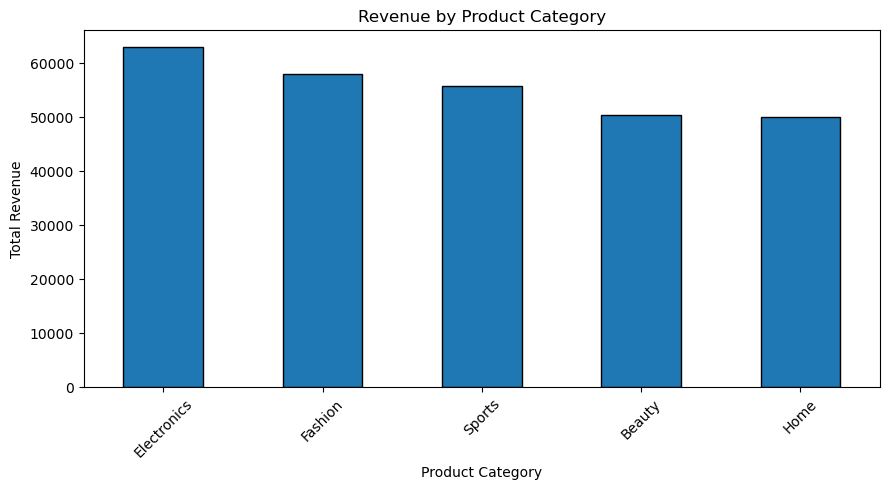

In [18]:
revenue_analysis.plot(
    kind="bar",
    figsize=(9, 5),
    edgecolor="black",
    title="Revenue by Product Category"
)

plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
print("MARKETING FUNNEL ANALYSIS - RECOMMENDATIONS")

print("\n1. Improve Add to Cart to Checkout conversion.")
print("2. Simplify the checkout process.")
print("3. Investigate payment failures and cart abandonment.")
print("4. Focus marketing campaigns on high-converting channels.")
print("5. Promote Electronics because it generates the highest revenue.")
print("6. Optimize campaigns for devices with lower conversion rates.")

MARKETING FUNNEL ANALYSIS - RECOMMENDATIONS

1. Improve Add to Cart to Checkout conversion.
2. Simplify the checkout process.
3. Investigate payment failures and cart abandonment.
4. Focus marketing campaigns on high-converting channels.
5. Promote Electronics because it generates the highest revenue.
6. Optimize campaigns for devices with lower conversion rates.
